# Median + ResNet50 + Grad-CAM

In [ ]:
!pip install grad-cam -q

import os
import cv2
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile

from google.colab import drive
from torchvision.models import resnet50, ResNet50_Weights
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import classification_report

In [ ]:
import random

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

g = torch.Generator()
g.manual_seed(SEED)

print(f"🌱 Seed di-set ke {SEED} — training sekarang seharusnya reproducible")

🌱 Seed di-set ke 42 — training sekarang seharusnya reproducible


In [ ]:
drive.mount('/content/drive')

zip_path     = '/content/drive/MyDrive/Dataset_Final.zip'
extract_base = '/content/dataset_fgadr'
os.makedirs(extract_base, exist_ok=True)

if os.path.exists(zip_path):
    print(f"Mengekstrak {zip_path} ...")
    with zipfile.ZipFile(zip_path, 'r') as zf:
        zf.extractall(extract_base)
    print("Proses unzip selesai!")
else:
    raise FileNotFoundError(f"ZIP tidak ditemukan: {zip_path}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Mengekstrak /content/drive/MyDrive/Dataset_Final.zip ...
Proses unzip selesai!


In [ ]:
INPUT_IMAGE_DIR = "/content/dataset_fgadr"

TRAIN_CSV = "/content/drive/MyDrive/train_local.csv"
VAL_CSV   = "/content/drive/MyDrive/val_local.csv"
TEST_CSV  = "/content/drive/MyDrive/test_local.csv"

ACTIVE_PREPRO = "median"

BATCH_SIZE    = 16
NUM_EPOCHS    = 100
LEARNING_RATE = 0.0001
WEIGHT_DECAY  = 1e-4
TARGET_SIZE   = 512

MODEL_SAVE_PATH = f'/content/drive/MyDrive/resnet50_DR_{ACTIVE_PREPRO}.pth'
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Device       : {DEVICE}")
print(f"Preprocessing: {ACTIVE_PREPRO}")
print(f"Epochs       : {NUM_EPOCHS}")

Device       : cuda
Preprocessing: median
Epochs       : 100


#Current Preprocessing
- Median Filter

In [ ]:
from torchvision import transforms

def prepro_median(bgr):
    # Median filter dengan kernel 5x5 untuk reduksi noise
    median = cv2.medianBlur(bgr, 5)
    return cv2.cvtColor(median, cv2.COLOR_BGR2RGB)

PREPRO_MAP = {
    'median'     : prepro_median,
}
prepro_fn = PREPRO_MAP[ACTIVE_PREPRO]

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# Augmentasi HANYA untuk train (menekan overfitting)
train_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((TARGET_SIZE, TARGET_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# Val / Test TANPA augmentasi (evaluasi harus deterministik)
eval_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((TARGET_SIZE, TARGET_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

print('Preprocessing [' + ACTIVE_PREPRO + '] siap! (train augmented, eval clean)')

Preprocessing [median] siap! (train augmented, eval clean)


In [ ]:
# --- PERBAIKAN BARU ---
LESION_MASK_FOLDERS = [
    "Microaneurysms_Masks",
    "HardExudate_Masks",
    "SoftExudate_Masks",
    "Hemohedge_Masks",
]
NUM_LESIONS = len(LESION_MASK_FOLDERS)

class DRLesionDataset(Dataset):
    def __init__(self, csv_path, img_dir, prepro_fn, transform_pipeline):
        df = pd.read_csv(csv_path)
        df['filename'] = df['image_path'].apply(lambda x: x.strip().split('\\')[-1])
        df['local_path'] = df['filename'].apply(lambda x: f"{img_dir}/Original_Images\\{x}")
        df = df[df['local_path'].apply(os.path.exists)].reset_index(drop=True)
        self.df = df
        self.prepro = prepro_fn
        self.img_dir = img_dir
        self.transform = transform_pipeline
        print(f"   → {len(self.df)} gambar valid dari {os.path.basename(csv_path)}")

    def __len__(self):
        return len(self.df)

    def _lesion_labels(self, filename):
        labels = []
        for folder in LESION_MASK_FOLDERS:
            mask_path = f"{self.img_dir}/{folder}\\{filename}"
            if os.path.exists(mask_path):
                m = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
                present = 1.0 if (m is not None and (m > 0).any()) else 0.0
            else:
                present = 0.0
            labels.append(present)
        return torch.tensor(labels, dtype=torch.float32)  # Output berupa tensor berukuran [4]

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        filename = row['filename']
        bgr = cv2.imread(row['local_path'])
        img_rgb = self.prepro(bgr)
        tensor_img = self.transform(img_rgb)
        lesion_tensor = self._lesion_labels(filename)
        return tensor_img, lesion_tensor

# Update pemanggilan inisialisasi dataset & loader di bawahnya:
print("\n📂 Loading datasets untuk Klasifikasi Multi-Label Lesi...")
train_dataset = DRLesionDataset(TRAIN_CSV, INPUT_IMAGE_DIR, prepro_fn, train_transform)
val_dataset   = DRLesionDataset(VAL_CSV,   INPUT_IMAGE_DIR, prepro_fn, eval_transform)
test_dataset  = DRLesionDataset(TEST_CSV,  INPUT_IMAGE_DIR, prepro_fn, eval_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, generator=g)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)


📂 Loading datasets untuk Klasifikasi Multi-Label Lesi...
   → 1289 gambar valid dari train_local.csv
   → 276 gambar valid dari val_local.csv
   → 277 gambar valid dari test_local.csv


In [ ]:
# Perhitungan pos_weight khusus untuk multi-label imbalance data
def compute_pos_weight(dataset):
    print("⏳ Menghitung distribusi bobot lesi (pos_weight)...")
    all_labels = torch.stack([dataset._lesion_labels(f) for f in dataset.df['filename']])
    pos = all_labels.sum(dim=0)
    neg = len(dataset) - pos
    pos_weight = neg / (pos + 1e-6)
    return pos_weight.to(DEVICE), all_labels

pos_weight_tensor, train_lesion_labels = compute_pos_weight(train_dataset)
print("Distribusi positif per lesi:", train_lesion_labels.sum(dim=0).tolist())
print("pos_weight per lesi:", pos_weight_tensor.tolist())

# Load ResNet50
model = resnet50(weights=ResNet50_Weights.IMAGENET1K_V1)

# Freeze layer awal
for param in model.parameters():
    param.requires_grad = False

# GANTI HEAD MODEL KE 4 OUTPUT (NUM_LESIONS)
model.fc = nn.Sequential(
    nn.Dropout(0.5),
    nn.Linear(model.fc.in_features, NUM_LESIONS)
)

# Unfreeze layer4 + fc untuk fine-tuning
for param in model.layer4.parameters():
    param.requires_grad = True
for param in model.fc.parameters():
    param.requires_grad = True

model = model.to(DEVICE)

# GANTI CRITERION MENJADI BCEWithLogitsLoss
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)

optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=20, gamma=0.1)
PATIENCE = 10

⏳ Menghitung distribusi bobot lesi (pos_weight)...
Distribusi positif per lesi: [992.0, 891.0, 433.0, 1018.0]
pos_weight per lesi: [0.2993951737880707, 0.44668909907341003, 1.976905345916748, 0.2662082612514496]


In [ ]:
best_val_loss = float('inf')
patience_counter = 0
history = {'train_loss':[], 'train_acc':[], 'val_loss':[], 'val_acc':[]}

print(f"\n🚀 Mulai training ResNet-50 Multi-Label (Resolusi {TARGET_SIZE}) ...\n")

for epoch in range(NUM_EPOCHS):
    model.train()
    train_loss, train_correct, train_total = 0, 0, 0

    for inputs, lesion_labels in train_loader:
        inputs, lesion_labels = inputs.to(DEVICE), lesion_labels.to(DEVICE)
        optimizer.zero_grad()
        outputs = model(inputs)                 # Logits shape: [B, 4]
        loss = criterion(outputs, lesion_labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        preds = (torch.sigmoid(outputs) > 0.5).float()
        train_correct += (preds == lesion_labels).sum().item()   # Per-label match
        train_total += lesion_labels.numel()
    scheduler.step()

    model.eval()
    val_loss, val_correct, val_total = 0, 0, 0
    with torch.no_grad():
        for inputs, lesion_labels in val_loader:
            inputs, lesion_labels = inputs.to(DEVICE), lesion_labels.to(DEVICE)
            outputs = model(inputs)
            loss = criterion(outputs, lesion_labels)

            val_loss += loss.item()
            preds = (torch.sigmoid(outputs) > 0.5).float()
            val_correct += (preds == lesion_labels).sum().item()
            val_total += lesion_labels.numel()

    t_acc = train_correct / train_total
    v_acc = val_correct / val_total
    t_l   = train_loss / len(train_loader)
    v_l   = val_loss / len(val_loader)

    history['train_loss'].append(t_l)
    history['train_acc'].append(t_acc)
    history['val_loss'].append(v_l)
    history['val_acc'].append(v_acc)

    print(f"Epoch [{epoch+1:2d}/{NUM_EPOCHS}]  Train → Loss: {t_l:.4f}  Acc: {t_acc:.4f} | Val → Loss: {v_l:.4f}  Acc: {v_acc:.4f}")

    if v_l < best_val_loss:
        best_val_loss = v_l
        patience_counter = 0
        torch.save(model.state_dict(), MODEL_SAVE_PATH)
        print(f"  💾 Model terbaik disimpan! Val Loss: {v_l:.4f}")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"\n⏹️ Early stopping di epoch {epoch+1}")
            break


🚀 Mulai training ResNet-50 Multi-Label (Resolusi 512) ...

Epoch [ 1/100]  Train → Loss: 0.4372  Acc: 0.6571 | Val → Loss: 0.4132  Acc: 0.6458
  💾 Model terbaik disimpan! Val Loss: 0.4132
Epoch [ 2/100]  Train → Loss: 0.3945  Acc: 0.6936 | Val → Loss: 0.4036  Acc: 0.7165
  💾 Model terbaik disimpan! Val Loss: 0.4036
Epoch [ 3/100]  Train → Loss: 0.3601  Acc: 0.7341 | Val → Loss: 0.4263  Acc: 0.6893
Epoch [ 4/100]  Train → Loss: 0.3404  Acc: 0.7510 | Val → Loss: 0.4338  Acc: 0.7201
Epoch [ 5/100]  Train → Loss: 0.3338  Acc: 0.7469 | Val → Loss: 0.3954  Acc: 0.7482
  💾 Model terbaik disimpan! Val Loss: 0.3954
Epoch [ 6/100]  Train → Loss: 0.3154  Acc: 0.7729 | Val → Loss: 0.4188  Acc: 0.7391
Epoch [ 7/100]  Train → Loss: 0.2952  Acc: 0.7878 | Val → Loss: 0.4128  Acc: 0.7382
Epoch [ 8/100]  Train → Loss: 0.2924  Acc: 0.7921 | Val → Loss: 0.4051  Acc: 0.7464
Epoch [ 9/100]  Train → Loss: 0.2814  Acc: 0.7933 | Val → Loss: 0.3994  Acc: 0.7681
Epoch [10/100]  Train → Loss: 0.2709  Acc: 0.8119

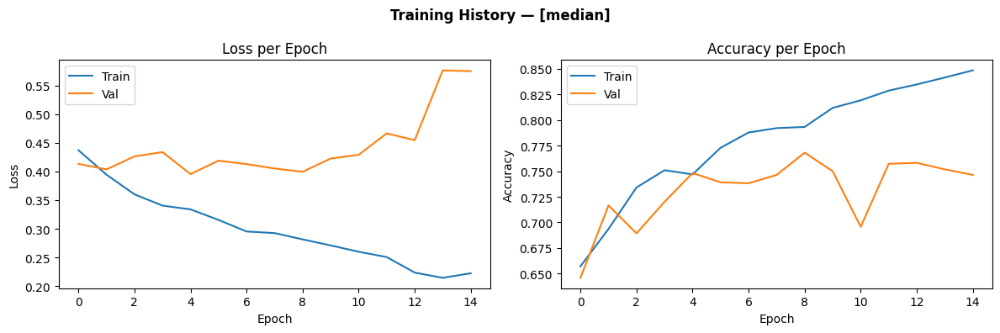

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history['train_loss'], label='Train')
ax[0].plot(history['val_loss'],   label='Val')
ax[0].set_title('Loss per Epoch')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Loss')
ax[0].legend()

ax[1].plot(history['train_acc'], label='Train')
ax[1].plot(history['val_acc'],   label='Val')
ax[1].set_title('Accuracy per Epoch')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Accuracy')
ax[1].legend()

plt.suptitle(f'Training History — [{ACTIVE_PREPRO}]', fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import classification_report, accuracy_score, hamming_loss, f1_score

# >>> PENTING: pakai bobot TERBAIK yang disimpan saat training, bukan epoch terakhir
model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))
model.eval()

targets_all, preds_all = [], []
with torch.no_grad():
    for inputs, lesion_labels in test_loader:
        inputs  = inputs.to(DEVICE)
        outputs = model(inputs)
        preds   = (torch.sigmoid(outputs) > 0.5).float()
        targets_all.append(lesion_labels.cpu().numpy())
        preds_all.append(preds.cpu().numpy())

targets_all = np.vstack(targets_all)
preds_all   = np.vstack(preds_all)

print('=' * 50)
print('   CLASSIFICATION REPORT - MULTI-LABEL LESIONS')
print('=' * 50)
print(classification_report(targets_all, preds_all, target_names=LESION_MASK_FOLDERS, zero_division=0))

# --- Akurasi ringkas (yang tadinya belum ada angka tunggalnya) ---
subset_acc    = accuracy_score(targets_all, preds_all)          # exact-match semua label benar
per_label_acc = (targets_all == preds_all).mean()               # rata-rata benar per label
hamming       = hamming_loss(targets_all, preds_all)
micro_f1      = f1_score(targets_all, preds_all, average='micro', zero_division=0)
macro_f1      = f1_score(targets_all, preds_all, average='macro', zero_division=0)

print('Subset accuracy (exact match) : ' + format(subset_acc * 100, '.2f') + '%')
print('Per-label accuracy            : ' + format(per_label_acc * 100, '.2f') + '%')
print('Hamming loss                  : ' + format(hamming, '.4f'))
print('Micro-F1                      : ' + format(micro_f1, '.4f'))
print('Macro-F1                      : ' + format(macro_f1, '.4f'))

   CLASSIFICATION REPORT - MULTI-LABEL LESIONS
                      precision    recall  f1-score   support

Microaneurysms_Masks       0.85      0.63      0.72       212
   HardExudate_Masks       0.92      0.77      0.84       197
   SoftExudate_Masks       0.70      0.48      0.57        98
     Hemohedge_Masks       0.97      0.76      0.85       224

           micro avg       0.89      0.69      0.78       731
           macro avg       0.86      0.66      0.75       731
        weighted avg       0.88      0.69      0.77       731
         samples avg       0.69      0.60      0.62       731

Subset accuracy (exact match) : 33.57%
Per-label accuracy            : 73.74%
Hamming loss                  : 0.2626
Micro-F1                      : 0.7760
Macro-F1                      : 0.7461


In [ ]:
import matplotlib.pyplot as plt

def denormalize(img_tensor):
    mean = np.array(IMAGENET_MEAN).reshape(3, 1, 1)
    std  = np.array(IMAGENET_STD).reshape(3, 1, 1)
    img  = img_tensor.cpu().numpy() * std + mean
    img  = np.clip(img, 0, 1)
    return np.transpose(img, (1, 2, 0))

def visualize_localization_results(orig_img_tensor, grayscale_cam, pred_mask, gt_mask, filename, lesion_name, metrics_dict):
    img_np = denormalize(orig_img_tensor)   # RGB 0-1 warna asli setelah preprocessing

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    title = ('Lokalisasi Lesi: ' + lesion_name + ' (' + filename + ')' + chr(10) +
             'IoU: ' + format(metrics_dict['iou'], '.2f') +
             ' | DSC: ' + format(metrics_dict['dsc'], '.2f') +
             ' | Sens: ' + format(metrics_dict['sens'], '.2f') +
             ' | Spec: ' + format(metrics_dict['spec'], '.2f'))
    fig.suptitle(title, fontsize=14, fontweight='bold')

    axes[0].imshow(img_np)
    axes[0].set_title('Original (preprocessed RGB)')
    axes[0].axis('off')

    heatmap = cv2.applyColorMap(np.uint8(255 * grayscale_cam), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    cam_blended = np.float32(heatmap) / 255 + np.float32(img_np)
    cam_blended = cam_blended / np.max(cam_blended)
    axes[1].imshow(cam_blended)
    axes[1].set_title('Grad-CAM Overlay')
    axes[1].axis('off')

    axes[2].imshow(pred_mask, cmap='gray')
    axes[2].set_title('Predicted Mask (thresh >= ' + str(GRADCAM_THRESHOLD) + ')')
    axes[2].axis('off')

    axes[3].imshow(gt_mask, cmap='gray')
    axes[3].set_title('Ground Truth Mask')
    axes[3].axis('off')

    plt.tight_layout()
    plt.show()

Grad-CAM localization eval (best weights, no-sigmoid)...
Evaluasi selesai.

     GRAD-CAM LOCALIZATION PERFORMANCE REPORT

Lesi: Microaneurysms_Masks (212 gambar)
   Mean IoU (coarse) : 0.95%
   Mean DSC (coarse) : 1.71%
   Sensitivity       : 42.01%
   Specificity       : 78.57%
   Pixel-level AUC   : 66.02%
   Pointing Game     : 3.30%   <- metrik utama lokalisasi

Lesi: HardExudate_Masks (197 gambar)
   Mean IoU (coarse) : 3.85%
   Mean DSC (coarse) : 6.89%
   Sensitivity       : 72.23%
   Specificity       : 83.98%
   Pixel-level AUC   : 84.51%
   Pointing Game     : 13.20%   <- metrik utama lokalisasi

Lesi: SoftExudate_Masks (98 gambar)
   Mean IoU (coarse) : 2.98%
   Mean DSC (coarse) : 5.57%
   Sensitivity       : 65.24%
   Specificity       : 87.69%
   Pixel-level AUC   : 82.65%
   Pointing Game     : 12.24%   <- metrik utama lokalisasi

Lesi: Hemohedge_Masks (224 gambar)
   Mean IoU (coarse) : 2.98%
   Mean DSC (coarse) : 5.38%
   Sensitivity       : 55.26%
   Specificity    

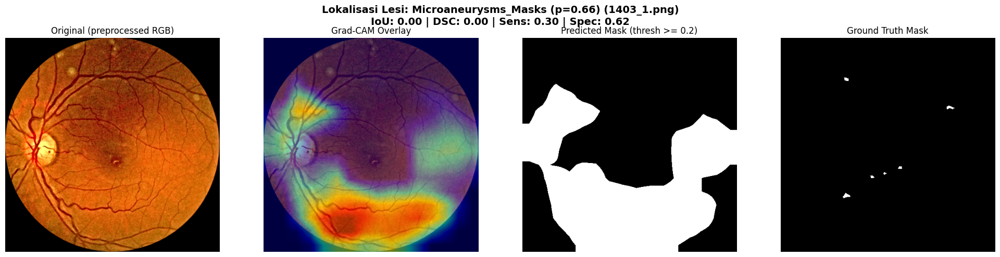

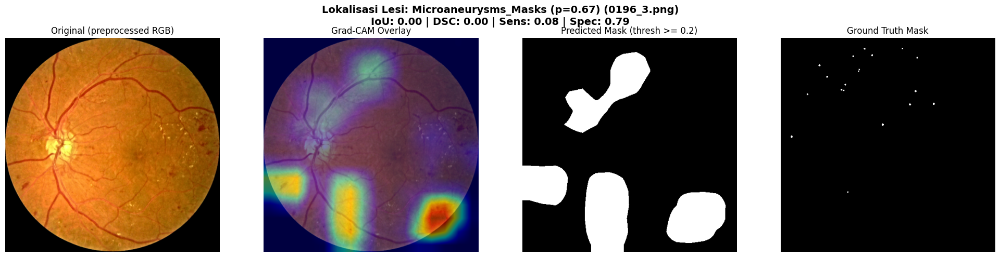

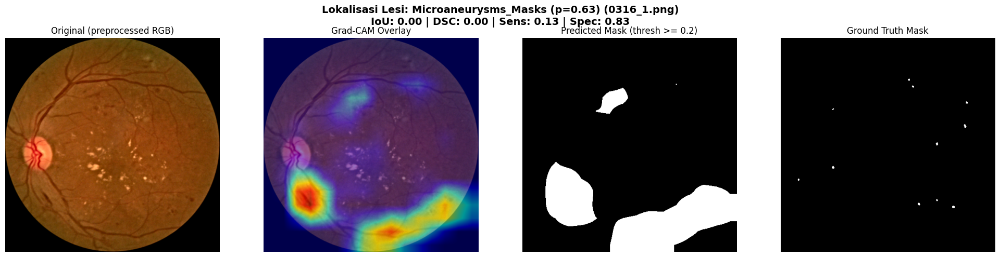

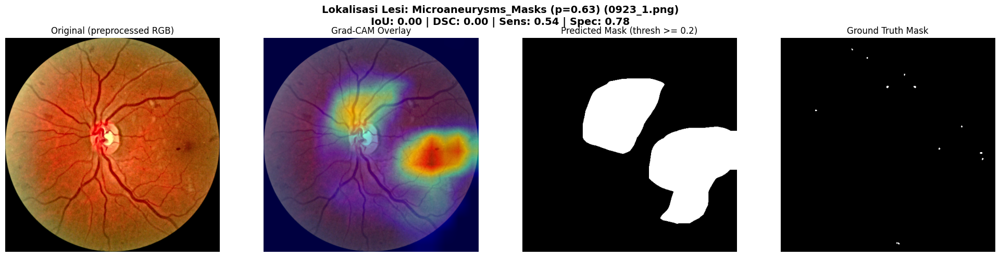

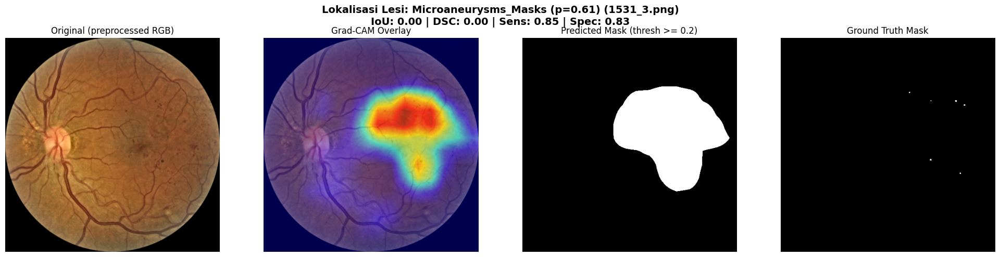

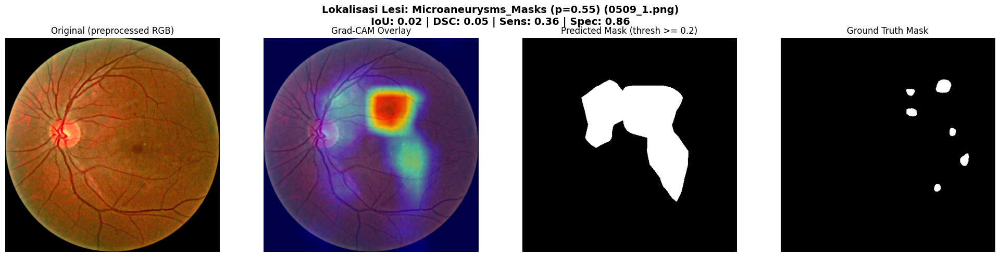

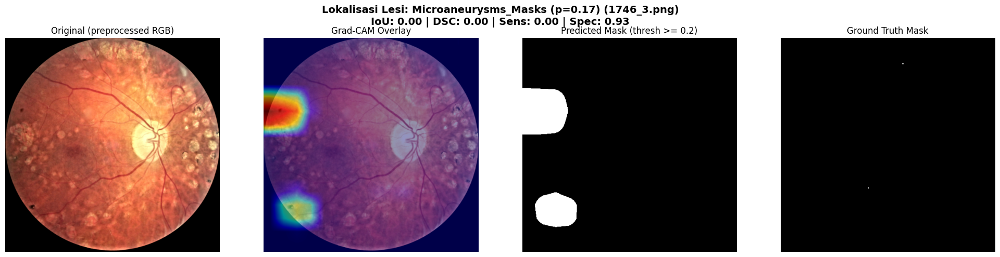

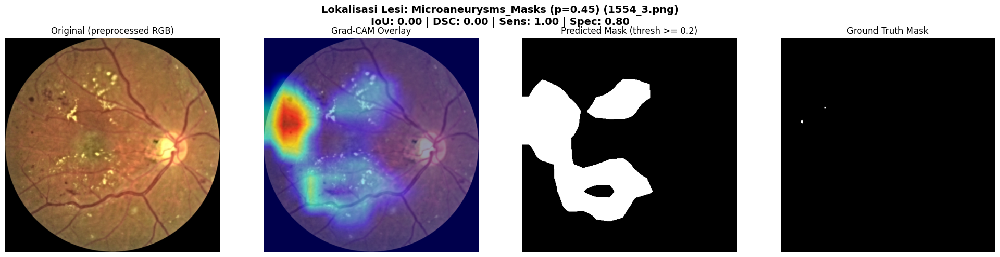


--- Lesi: HardExudate_Masks ---


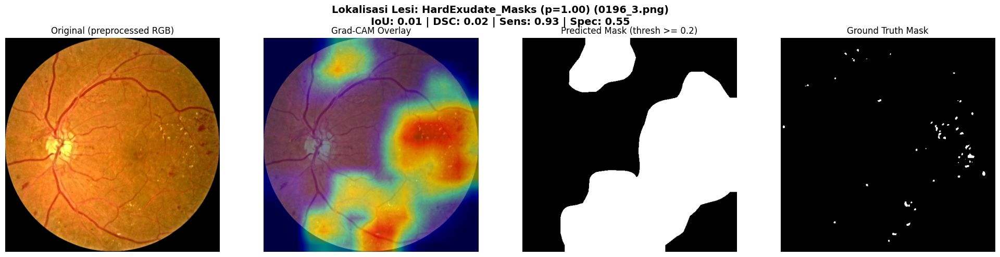

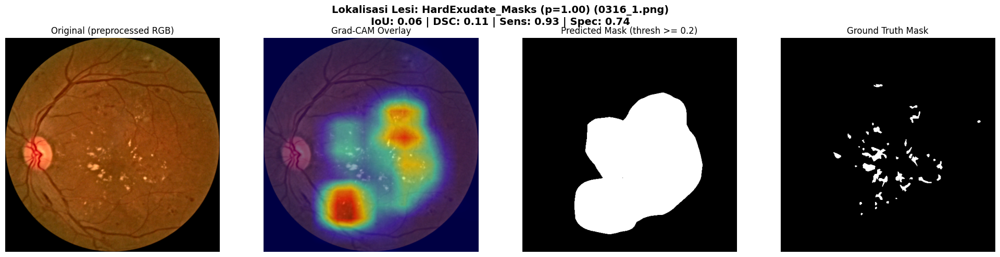

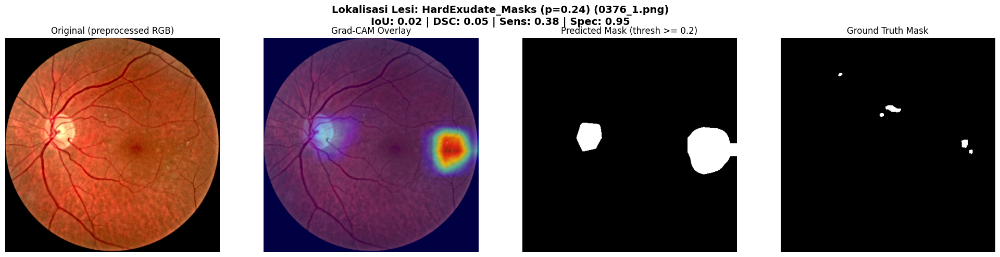

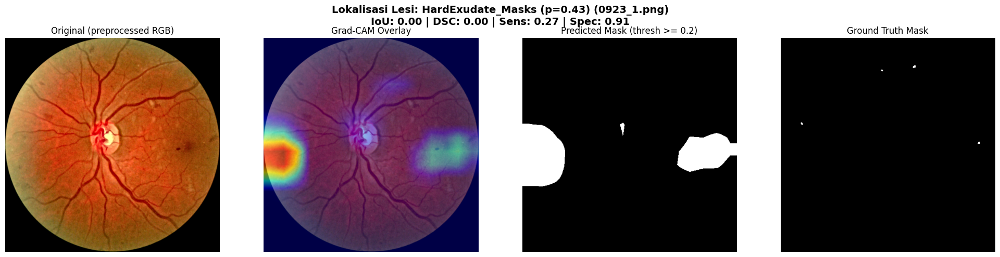

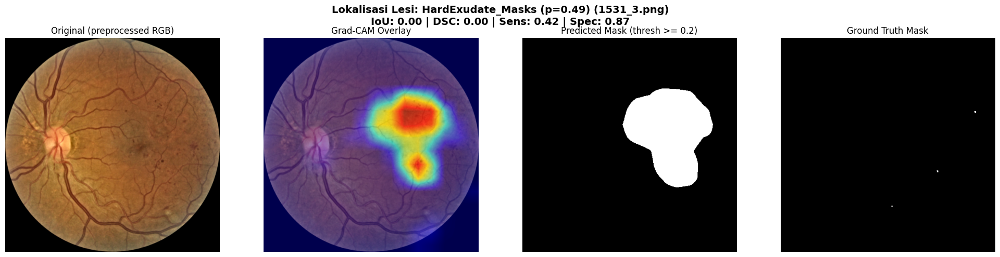

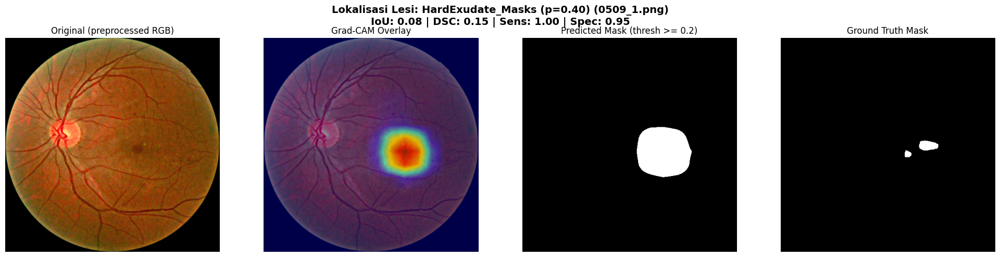

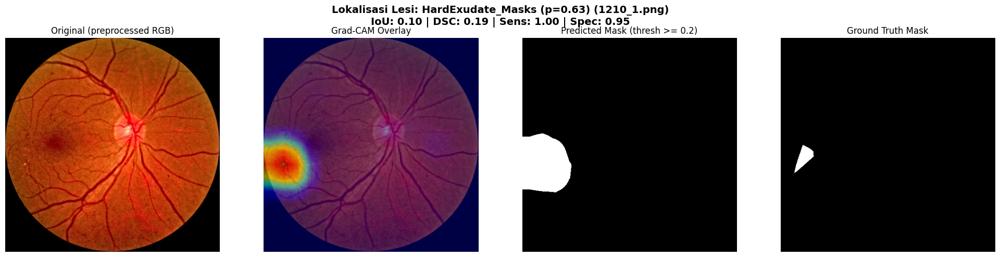

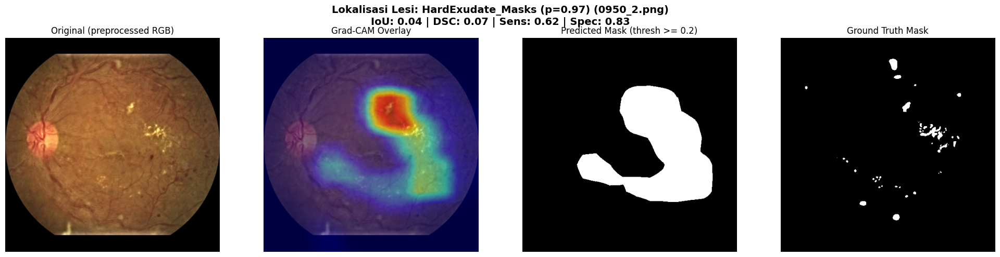


--- Lesi: SoftExudate_Masks ---


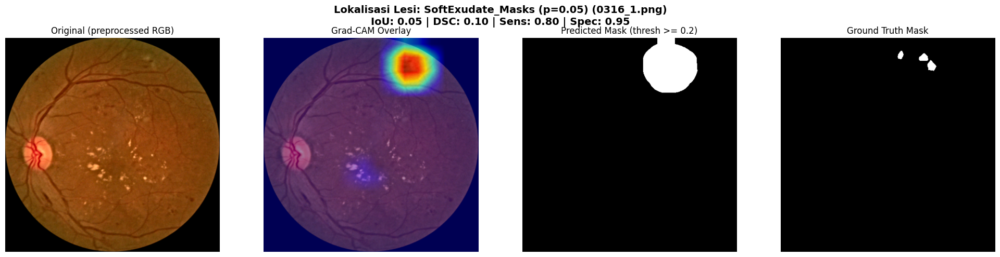

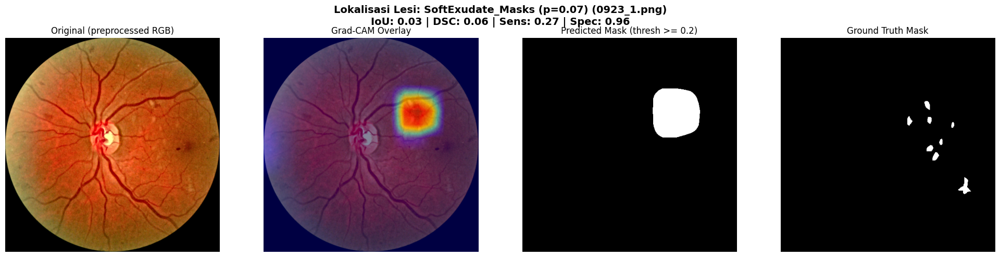

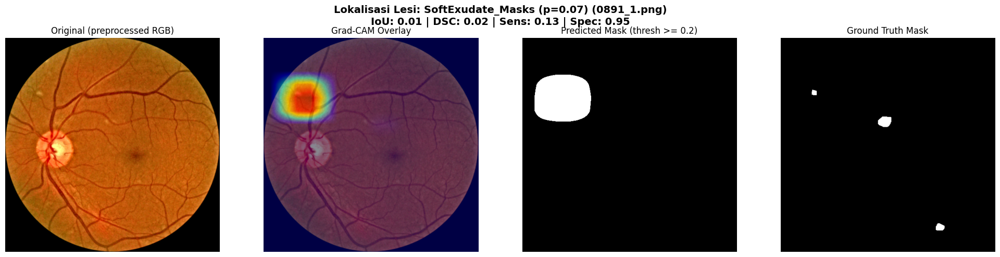

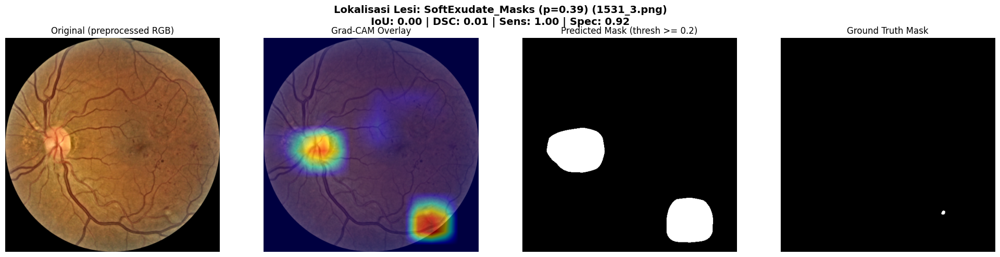

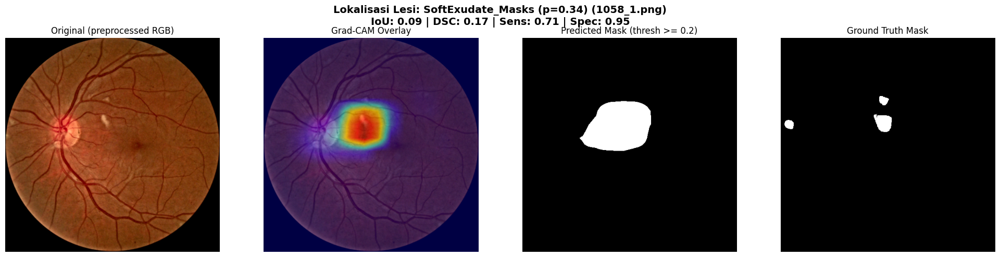

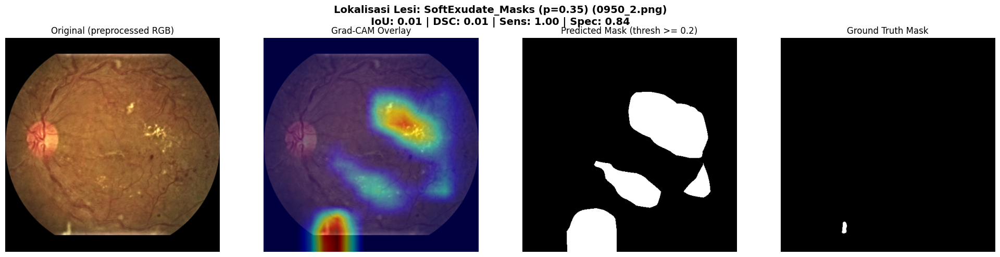

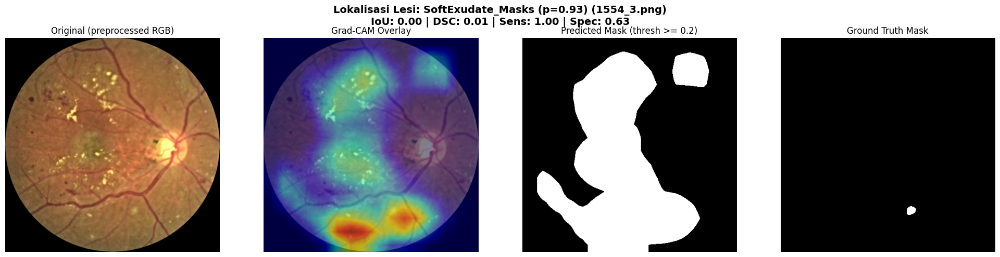

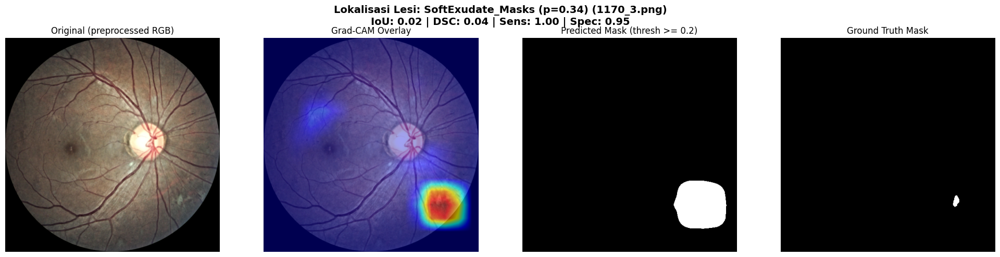


--- Lesi: Hemohedge_Masks ---


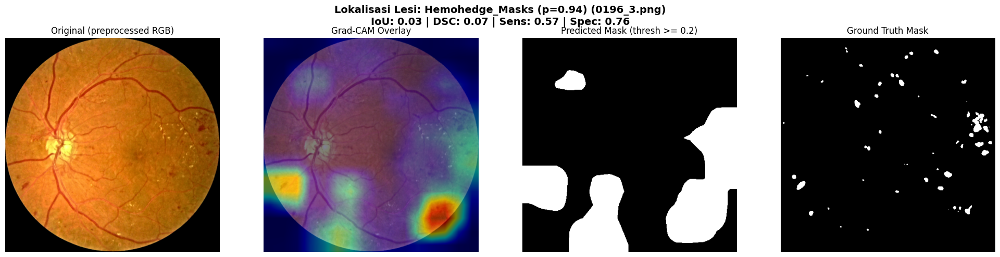

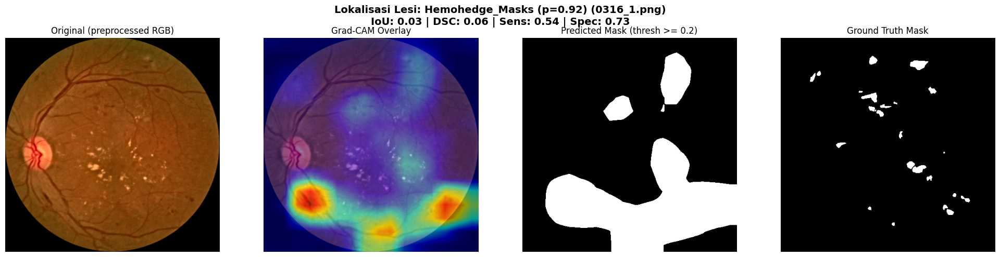

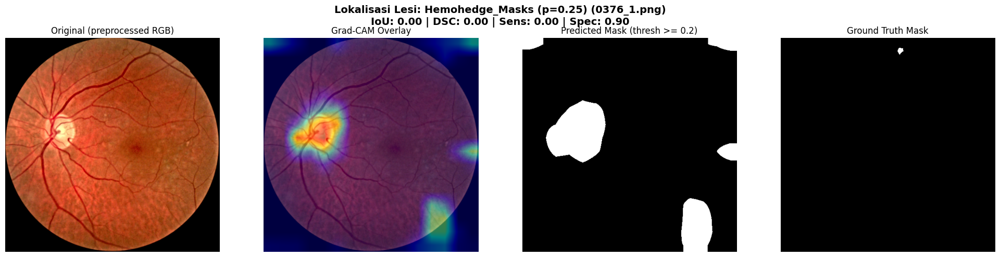

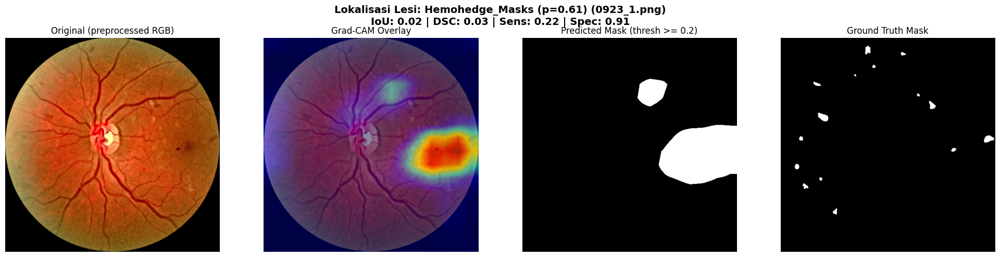

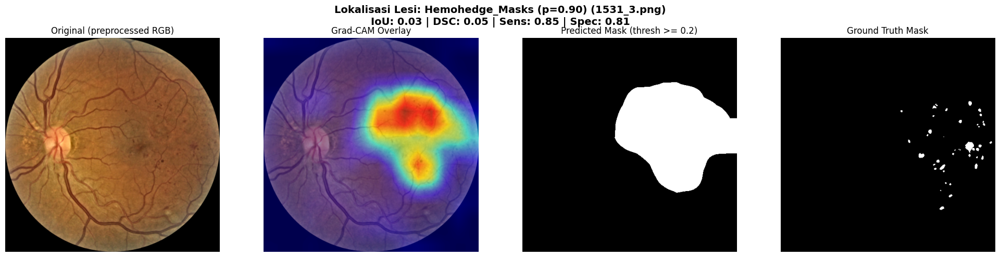

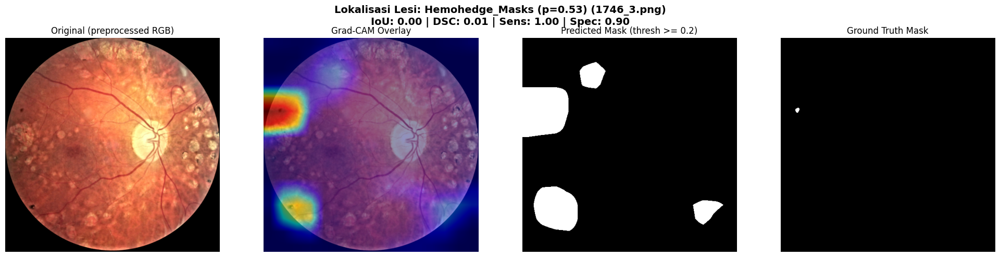

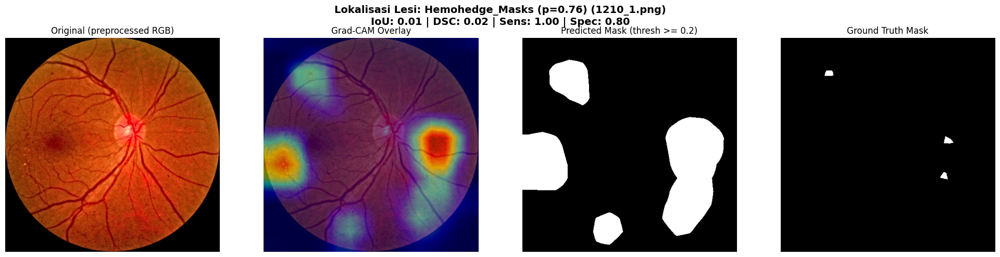

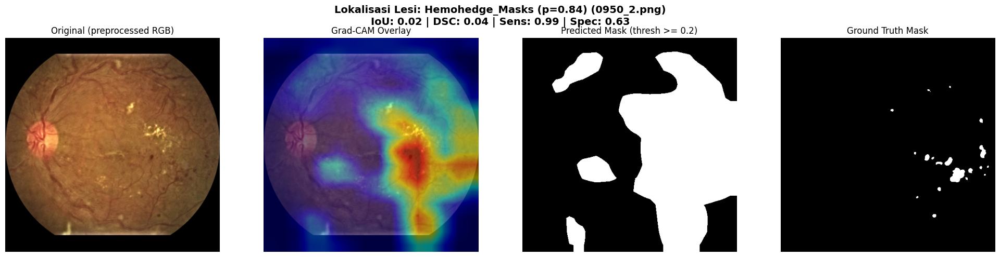

In [ ]:
# >>> reload best weights lagi (kalau cell ini dijalankan terpisah)
model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))
model.eval()

GRADCAM_THRESHOLD = 0.2

# Multi-label: target langsung ke LOGIT mentah (TANPA sigmoid) supaya gradien tidak jenuh.
# ClassifierOutputTarget sudah memilih 1 kelas -> tidak perlu wrapper.
target_layers = [model.layer4[-1]]
cam = GradCAM(model=model, target_layers=target_layers)

def calculate_mask_metrics(pred_mask, gt_mask):
    pred_mask = (pred_mask > 0).astype(np.uint8)
    gt_mask   = (gt_mask > 0).astype(np.uint8)
    TP = np.sum((pred_mask == 1) & (gt_mask == 1))
    FP = np.sum((pred_mask == 1) & (gt_mask == 0))
    FN = np.sum((pred_mask == 0) & (gt_mask == 1))
    TN = np.sum((pred_mask == 0) & (gt_mask == 0))
    s = 1e-6
    iou  = (TP + s) / (TP + FP + FN + s)
    dsc  = (2.0 * TP + s) / (2.0 * TP + FP + FN + s)
    sens = (TP + s) / (TP + FN + s)
    spec = (TN + s) / (TN + FP + s)
    return iou, dsc, sens, spec

def pointing_game_hit(cam_map, gt_mask):
    # apakah titik puncak heatmap jatuh di dalam GT mask
    y, x = np.unravel_index(np.argmax(cam_map), cam_map.shape)
    return 1.0 if gt_mask[y, x] > 0 else 0.0

class_metrics = {i: {'iou': [], 'dsc': [], 'sens': [], 'spec': [], 'auc': [], 'pg': []}
                 for i in range(NUM_LESIONS)}

print('Grad-CAM localization eval (best weights, no-sigmoid)...')
for idx in range(len(test_dataset)):
    input_tensor, _ = test_dataset[idx]
    filename        = test_dataset.df.iloc[idx]['filename']
    input_batch     = input_tensor.unsqueeze(0).to(DEVICE)

    for class_idx in range(NUM_LESIONS):
        folder    = LESION_MASK_FOLDERS[class_idx]
        mask_path = test_dataset.img_dir + "/" + folder + chr(92) + filename
        if not os.path.exists(mask_path):
            continue
        gt = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        if gt is None or not (gt > 0).any():
            continue
        gt = cv2.resize(gt, (TARGET_SIZE, TARGET_SIZE), interpolation=cv2.INTER_NEAREST)
        gt = (gt > 0).astype(np.float32)

        targets       = [ClassifierOutputTarget(class_idx)]
        grayscale_cam = cam(input_tensor=input_batch, targets=targets)[0]
        pred_mask     = (grayscale_cam >= GRADCAM_THRESHOLD).astype(np.float32)

        iou, dsc, sens, spec = calculate_mask_metrics(pred_mask, gt)
        try:
            auc = roc_auc_score(gt.flatten(), grayscale_cam.flatten())
        except ValueError:
            auc = 0.5
        pg = pointing_game_hit(grayscale_cam, gt)

        m = class_metrics[class_idx]
        m['iou'].append(iou); m['dsc'].append(dsc); m['sens'].append(sens)
        m['spec'].append(spec); m['auc'].append(auc); m['pg'].append(pg)
print('Evaluasi selesai.')

# ---------- REKAP PER LESI ----------
print('')
print('=' * 70)
print('     GRAD-CAM LOCALIZATION PERFORMANCE REPORT')
print('=' * 70)
for class_idx in range(NUM_LESIONS):
    m = class_metrics[class_idx]
    name = LESION_MASK_FOLDERS[class_idx]
    if len(m['iou']) == 0:
        print('')
        print('Lesi: ' + name + ' -> tidak ada data positif di test set.')
        continue
    print('')
    print('Lesi: ' + name + ' (' + str(len(m['iou'])) + ' gambar)')
    print('   Mean IoU (coarse) : ' + format(np.mean(m['iou'])  * 100, '.2f') + '%')
    print('   Mean DSC (coarse) : ' + format(np.mean(m['dsc'])  * 100, '.2f') + '%')
    print('   Sensitivity       : ' + format(np.mean(m['sens']) * 100, '.2f') + '%')
    print('   Specificity       : ' + format(np.mean(m['spec']) * 100, '.2f') + '%')
    print('   Pixel-level AUC   : ' + format(np.mean(m['auc'])  * 100, '.2f') + '%')
    print('   Pointing Game     : ' + format(np.mean(m['pg'])   * 100, '.2f') + '%   <- metrik utama lokalisasi')

# ---------- VISUALISASI: N contoh per KELAS LESI (bukan cuma top-1 per gambar) ----------
# Diubah dari "4 gambar total (top prediksi per gambar)" menjadi
# "N gambar PER lesi" supaya tiap kelas lesi (MA, HE, EX, SE) punya representasi
# visual yang cukup di skripsi, bukan didominasi kelas yang paling sering
# menang sebagai top-1 prediction.
SAMPLES_PER_LESION = 8  # -> total = SAMPLES_PER_LESION x NUM_LESIONS gambar

print('')
print(f'Contoh visualisasi ({SAMPLES_PER_LESION} gambar per lesi, total target '
      f'{SAMPLES_PER_LESION * NUM_LESIONS} gambar):')

        # Hanya ambil gambar yang benar-benar punya GT mask positif untuk lesi ini
        if not os.path.exists(mask_path):
            continue
        gt = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        if gt is None or not (gt > 0).any():
            continue
        gt = cv2.resize(gt, (TARGET_SIZE, TARGET_SIZE), interpolation=cv2.INTER_NEAREST)
        gt = (gt > 0).astype(np.float32)

        input_tensor, _ = test_dataset[idx]
        input_batch      = input_tensor.unsqueeze(0).to(DEVICE)

        with torch.no_grad():
            probs = torch.sigmoid(model(input_batch))[0]
        prob_this_class = float(probs[class_idx])

        targets       = [ClassifierOutputTarget(class_idx)]
        grayscale_cam = cam(input_tensor=input_batch, targets=targets)[0]
        pred_mask     = (grayscale_cam >= GRADCAM_THRESHOLD).astype(np.float32)
        iou, dsc, sens, spec = calculate_mask_metrics(pred_mask, gt)

        label = folder + ' (p=' + format(prob_this_class, '.2f') + ')'
        visualize_localization_results(input_tensor, grayscale_cam, pred_mask, gt,
                                       filename, label,
                                       {'iou': iou, 'dsc': dsc, 'sens': sens, 'spec': spec})
        shown += 1

    if shown < SAMPLES_PER_LESION:
        print(f'   (hanya ditemukan {shown} gambar dengan GT mask positif untuk lesi ini di test set)')